In [ ]:

# MARGENTO #GraphPoem @ DHSI 2023 GNODE


In [ ]:



The script trains GNODE to predict the concatenated feature vector (embedding + scaled phonological features). Since embeddings themselves were pre-normalized by SBERT, we only scaled phonological channels.

I set beta = 1.0 for the integration interval so the ODE sees an “event” forcing — we can vary this (e.g., 0 → 1 ramp, gaussian kernel) later. Beta was injected as a constant per-node scalar channel.

This uses dense adjacency and odeint (not sparse). For N ~ a few hundred this is fine. For 2k nodes we will want sparse ops or smaller latent dims and GPU.

The dataset is the minimal PRE→EVENT two-step setup. You can expand to multiple timepoints or sliding windows easily.

The model logs saved:
margento_graphpoem_gnode_event3_model.pth, margento_graphpoem_gnode_event3_pred_x1.npy, margento_graphpoem_gnode_event3_true_x1.npy, and gnode_event3_loss.png.

Future upgrads:

replace single-step training with multi-step teacher-forcing on a longer time-series,

add a β time-profile (Gaussian around the event),

implement sparse operations with PyTorch sparse or PyG.

In [ ]:
!pip install torchdiffeq

In [ ]:

import os, pickle, math, time
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
from torchdiffeq import odeint
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [ ]:

import torch
torch.set_default_dtype(torch.float32)


if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)


Device: mps


In [ ]:

# ----------------------------
# USER-SPECIFIED FILES (from you)
# ----------------------------
emb_prev_f = "margento_graphpoem_dhsi23_embeddings_window_prev_to_singularity_3.npy"
emb_evt_f  = "margento_graphpoem_dhsi23_embeddings_singularity_3.npy"

phon_prev_f = "margento_graphpoem_dhsi23_window_previous_to_singularity_3_phonological_feats.npy"
phon_evt_f  = "margento_graphpoem_dhsi23_singularity_3_phonological_feats.npy"

# REPLACE the ones below W POEM-ONLY MATRICES (FOR THIS STAGE)
# A_prev_f = "margento_graphpoem_dhsi23_adjacency_matrix_window_prev_to_singularity_3.npy"
# A_evt_f  = "margento_graphpoem_dhsi23_adjacency_matrix_singularity_3.npy"

A_prev_f = "margento_graphpoem_dhsi23_semantic_n_sonic_matrix_window_previous_to_singularity_3.npy"
A_evt_f = "margento_graphpoem_dhsi23_adjacency_matrix_singularity_3_poems.npy"


poems_prev_f = "margento_graphpoem_dhsi23_valid_poems_window_prev_to_singualrity_3.pkl"
poems_evt_f  = "margento_graphpoem_dhsi23_valid_poems_singualrity_3.pkl"

users_prev_f = "margento_graphpoem_dhsi23_users_window_prev_to_singularity_3.pkl"   # optional diagnostics
users_evt_f  = "margento_graphpoem_dhsi23_users_singularity_3.pkl"               # optional

In [ ]:



# ----------------------------
# 0. Load data (robustly)
# ----------------------------
def load_npy(path):
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    return np.load(path, allow_pickle=True)

def load_pkl(path):
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)

print("Loading files...")
emb_prev = load_npy(emb_prev_f)   # shape (M_prev, E)
emb_evt  = load_npy(emb_evt_f)    # shape (M_evt, E)
phon_prev = load_npy(phon_prev_f) # shape (M_prev, P)
phon_evt  = load_npy(phon_evt_f)  # shape (M_evt, P)

A_prev = load_npy(A_prev_f)       # shape (M_prev, M_prev) or similar
A_evt  = load_npy(A_evt_f)

valid_poems_prev = load_pkl(poems_prev_f)
valid_poems_evt  = load_pkl(poems_evt_f)

users_prev = load_pkl(users_prev_f)
users_evt  = load_pkl(users_evt_f)

print("Shapes:")
print(" emb_prev:", getattr(emb_prev,'shape',None))
print(" emb_evt: ", getattr(emb_evt,'shape',None))
print(" phon_prev:", getattr(phon_prev,'shape',None))
print(" phon_evt:", getattr(phon_evt,'shape',None))
print(" A_prev:", getattr(A_prev,'shape',None))
print(" A_evt: ", getattr(A_evt,'shape',None))
print(" #poems prev:", len(valid_poems_prev) if valid_poems_prev is not None else None)
print(" #poems evt: ", len(valid_poems_evt)  if valid_poems_evt is not None else None)

Loading files...
Shapes:
 emb_prev: (42, 512)
 emb_evt:  (45, 512)
 phon_prev: (42, 13)
 phon_evt: (45, 13)
 A_prev: ()
 A_evt:  ()
 #poems prev: 42
 #poems evt:  45


In [ ]:
# print(A_prev)
A_evt

array(<45x45 sparse matrix of type '<class 'numpy.float64'>'
	with 360 stored elements in Compressed Sparse Row format>, dtype=object)

In [ ]:
print(A_evt)

  (0, 6)	1.0
  (0, 7)	1.0
  (0, 25)	0.24995621807292323
  (0, 27)	0.27050682158492284
  (0, 30)	0.222921969000193
  (0, 31)	0.23476103007440308
  (0, 33)	0.24503408248694517
  (0, 44)	0.4108504209984212
  (1, 16)	0.1700270367523111
  (1, 22)	0.5471927175101173
  (1, 35)	0.30239820912165744
  (1, 37)	0.2410095168315579
  (1, 38)	0.18887097675993544
  (1, 39)	0.3692284566353358
  (1, 40)	0.28777387348349903
  (1, 41)	0.5048509626319515
  (2, 4)	0.564676799265266
  (2, 5)	0.5285320840863643
  (2, 8)	0.47820902355158995
  (2, 24)	0.5795104209064404
  (2, 25)	0.496942556566959
  (2, 30)	0.5638049338272951
  (2, 31)	0.5423918758597279
  (2, 44)	0.49943067839888666
  (3, 9)	0.47983883643424385
  :	:
  (41, 40)	0.2887834949661474
  (42, 2)	0.3673962629933515
  (42, 4)	0.3217818911115776
  (42, 5)	0.3264520532623354
  (42, 8)	0.31571648750877146
  (42, 21)	0.36914641527527436
  (42, 23)	0.3033589382210177
  (42, 30)	0.2691837675020142
  (42, 44)	0.47368746166361825
  (43, 3)	0.33073302866645543

In [ ]:
A_evt.shape # 0-dim NumPy array containing the sparse matrix as its single element

()

In [ ]:
A_evt = A_evt.item()
A_prev = A_prev.item()

In [ ]:
print(A_evt.shape, A_prev.shape)

(45, 45) (42, 42)


In [ ]:

# ----------------------------
# 1. Build union poem list and index maps
# ----------------------------
poems_prev = valid_poems_prev if valid_poems_prev is not None else []
poems_evt  = valid_poems_evt  if valid_poems_evt is not None else []

union_poems = []
seen = set()
for p in poems_prev + poems_evt:
    if p not in seen:
        union_poems.append(p); seen.add(p)

N = len(union_poems)
print("Union poem count N =", N)

idx_prev = {p:i for i,p in enumerate(poems_prev)}
idx_evt  = {p:i for i,p in enumerate(poems_evt)}
idx_union = {p:i for i,p in enumerate(union_poems)}

# find shared poem(s)
shared = list(set(poems_prev).intersection(set(poems_evt)))
print("Shared poems (intersection):", shared)

Union poem count N = 78
Shared poems (intersection): ['qiu_jin_pusaman_a_message_for_a_female_friend_from_chinese_trans_yilin_wang_poem_1.txt', 'place_rachel_blau_duplessis_draft_65_that_japanese_language_tao.txt', 'sagawa_chika_dark_song_from_japanese_trans_sawako_nakayasu_poem_2.txt', 'satu-taskinen_bio.txt', 'qiu_jin_reflections_from_chinese_trans_yilin_wang_poem_3.txt', 'place_rachel_by_matthew_arnold_paris_provence_french_riviera.txt', 'sagawa_chika_ocean_angel_from_japanese_trans_sawako_nakayasu_poem_3.txt', 'satu-taskinen_interview.txt', 'place_oliver_goldsmith_france.txt']


In [ ]:

# ----------------------------
# 2. Build aligned embeddings & phon features
# ----------------------------
# Embedding dimensionality check
E = emb_prev.shape[1] if emb_prev is not None else emb_evt.shape[1]
P = phon_prev.shape[1] if phon_prev is not None else phon_evt.shape[1]

X_prev = np.zeros((N, E + P), dtype=float)
X_evt  = np.zeros((N, E + P), dtype=float)

# fill PRE
for p, i_union in idx_union.items():
    if p in idx_prev:
        i_local = idx_prev[p]
        evec = emb_prev[i_local]
        pvec = phon_prev[i_local]
        X_prev[i_union, :E] = evec
        X_prev[i_union, E:] = pvec
    # else stays zero (pad)

# fill EVT
for p, i_union in idx_union.items():
    if p in idx_evt:
        i_local = idx_evt[p]
        evec = emb_evt[i_local]
        pvec = phon_evt[i_local]
        X_evt[i_union, :E] = evec
        X_evt[i_union, E:] = pvec

# Optionally scale phon features (important: embeddings are normalized already)
scaler_phon = StandardScaler()

# Only scale rows where phon data exists (avoid scaling zeros only rows)
mask_prev = np.array([p in idx_prev for p in union_poems])
mask_evt  = np.array([p in idx_evt  for p in union_poems])
mask_any = mask_prev | mask_evt

if mask_any.sum() > 0:
    phon_stack = np.vstack([X_prev[mask_any, E:], X_evt[mask_any, E:]])
    scaler_phon.fit(phon_stack)
    X_prev[mask_any, E:] = scaler_phon.transform(X_prev[mask_any, E:])
    X_evt[mask_any, E:]  = scaler_phon.transform(X_evt[mask_any, E:])

print("Built X_prev, X_evt shapes:", X_prev.shape, X_evt.shape)

# ----------------------------
# 3. Align adjacency matrices into union ordering
# ----------------------------
def align_adj(A_local, poems_local):
    """
    A_local: square matrix (M_local x M_local)
    poems_local: list of length M_local in same order as A_local
    returns A_union (N x N) where union ordering is union_poems
    """
    M_local = len(poems_local)
    A_out = np.zeros((N, N), dtype=float)
    if A_local is None or M_local == 0:
        return A_out
    # sanity: if sizes match, assume the local order corresponds to poems_local
    local_idx_map = {p:i for i,p in enumerate(poems_local)}
    for i_local, pi in enumerate(poems_local):
        ui = idx_union[pi]
        for j_local, pj in enumerate(poems_local):
            uj = idx_union[pj]
            A_out[ui, uj] = float(A_local[i_local, j_local])
    return A_out

A_prev_union = align_adj(A_prev, poems_prev)
A_evt_union  = align_adj(A_evt,  poems_evt)

print("Aligned adjacency shapes:", A_prev_union.shape, A_evt_union.shape)

# symmetrize if needed
A_prev_union = (A_prev_union + A_prev_union.T) / 2.0
A_evt_union  = (A_evt_union  + A_evt_union.T)  / 2.0

# normalize adjacency to [0,1] if necessary (avoid huge scales)
def norm01(A):
    if A.max() > 0:
        return A / float(A.max())
    return A

A_prev_union = norm01(A_prev_union)
A_evt_union  = norm01(A_evt_union)

# convert to torch tensors
X_prev_t = torch.tensor(X_prev, dtype=torch.float32, device=device)
X_evt_t  = torch.tensor(X_evt, dtype=torch.float32, device=device)
A_prev_t = torch.tensor(A_prev_union, dtype=torch.float32, device=device)
A_evt_t  = torch.tensor(A_evt_union,  dtype=torch.float32, device=device)

Built X_prev, X_evt shapes: (78, 525) (78, 525)
Aligned adjacency shapes: (78, 78) (78, 78)


In [ ]:


# ----------------------------
# 4. GNODE Model (compact variant for PRE->EVENT)
# ----------------------------
class SimpleGraphConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim)
        self.U = nn.Linear(in_dim, out_dim, bias=False)
        self.act = nn.ReLU()
    def forward(self, X, A):
        # left normalize A
        rs = A.sum(dim=1, keepdim=True) + 1e-12
        A_norm = A / rs
        agg = torch.matmul(A_norm, X)
        out = self.W(agg) + self.U(X)
        return self.act(out)

class GNODEFunc(nn.Module):
    def __init__(self, latent_dim, hidden_dim):
        super().__init__()
        self.gc1 = SimpleGraphConv(latent_dim + 1, hidden_dim)
        self.gc2 = SimpleGraphConv(hidden_dim, latent_dim)
        # self.norm = nn.LayerNorm(latent_dim)
        self.norm = nn.LayerNorm(latent_dim).float()
    def forward(self, t, zflat):
        N = current_A.size(0)
        latent = zflat.view(N, -1)
        beta_chan = current_beta.view(N,1)
        zin = torch.cat([latent, beta_chan], dim=1)
        h = self.gc1(zin, current_A)
        dz = self.gc2(h, current_A)
        return self.norm(dz).view(-1)

class GNODE(nn.Module):
    def __init__(self, feat_dim, latent_dim=64, hidden_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(feat_dim, latent_dim), nn.ReLU(), nn.Linear(latent_dim, latent_dim))
        self.odefunc = GNODEFunc(latent_dim, hidden_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, latent_dim), nn.ReLU(), nn.Linear(latent_dim, feat_dim))
    def forward(self, x0, A_seq, beta_seq, t_seq):
        # x0: [N, F], A_seq: list of [N,N] or callable, beta_seq: list scalars
        N = x0.size(0)
        x0 = x0.to(device, dtype=torch.float32)
        # z0 = self.encoder(x0)               # [N, latent]
        z0 = self.encoder(x0).float()
        zcur = z0.view(-1)
        zs = []
        tpoints = t_seq.cpu().numpy().tolist()
        for i in range(1, len(tpoints)):
            t0 = tpoints[i-1]; t1 = tpoints[i]
            # set global adjacency and beta for interval
            global current_A, current_beta
            A_t = A_seq[i-1] if not callable(A_seq) else A_seq(t0)
            if not isinstance(A_t, torch.Tensor):
                A_t = torch.tensor(A_t, device=device)
                # force float32 on MPS
            current_A = A_t.to(device=device, dtype=torch.float32)
            bval = beta_seq[i-1] if not callable(beta_seq) else beta_seq(t0)
            if isinstance(bval, (float, int)):
                current_beta = torch.ones(N, 1, device=device) * float(bval)
            else:
                current_beta = torch.tensor(bval, device=device).view(N,1)
            # force float32
            current_beta = current_beta.to(device=device, dtype=torch.float32)
            tspan = torch.tensor([t0, t1], device=device, dtype=torch.float32)
            zcur = zcur.to(device, dtype=torch.float32)
            # print(
                # "DEBUG:",
                # "zcur:", zcur.dtype,
                # "A:", current_A.dtype,
                # "beta:", current_beta.dtype,
                # "tspan:", tspan.dtype
            # )
            atol = torch.tensor(1e-6, dtype=torch.float32, device=device)
            rtol = torch.tensor(1e-4, dtype=torch.float32, device=device)
            options = {'dtype': torch.float32}   # force solver dtype
            zt = odeint(self.odefunc, zcur, tspan, atol=atol, rtol=rtol, options=options)
            zcur = zt[-1]
            zs.append(zcur.view(N, -1))
        preds = []
        for z in zs:
            preds.append(self.decoder(z))
        preds_full = torch.cat([x0.unsqueeze(0), torch.stack(preds, dim=0)], dim=0)
        return preds_full

# ----------------------------
# 5. Prepare single-step dataset PRE -> EVENT
# ----------------------------
# We'll use times = [0.0, 1.0], A_seq = [A_prev], beta_seq = [0->1]
times = torch.tensor([0.0, 1.0], dtype=torch.float32)
A_seq = [A_prev_t]
beta_seq = [0.0]   # beta for interval between t0->t1 (we'll pass 0.0 here but set injection at t1 via training targets)
# To make the event explicit we set beta value to 1.0 in the integration step (use beta_seq=[1.0] ideally).
# We'll use beta=1.0 so the ODE knows the interval is "eventful"
beta_seq = [1.0]

# target is X_evt_t (node features at t1)
x0 = X_prev_t
x_target = X_evt_t


In [ ]:


# ----------------------------
# 6. Instantiate model + train
# ----------------------------
feat_dim = X_prev.shape[1]
# model = GNODE(feat_dim=feat_dim, latent_dim=64, hidden_dim=128).to(device)
model = GNODE(feat_dim).to(device)
model = model.float()
opt = optim.Adam(model.parameters(), lr=1e-3)
mse = nn.MSELoss()

x0 = x0.to(device).float()
x_target = x_target.to(device).float()

A_seq = [A.to(device).float() for A in A_seq]  # if tensor
beta_seq = [float(b) for b in beta_seq]
times = times.to(device).float()

# Training: map x0 + A_prev -> predict x1
n_epochs = 200
loss_history = []
print("Training GNODE PRE->EVENT on union N=", N)

for ep in range(1, n_epochs+1):
    model.train()
    opt.zero_grad()
    preds = model(x0, A_seq, beta_seq, times)   # preds shape [2, N, F]
    x1_hat = preds[-1]
    loss = mse(x1_hat, x_target)
    loss.backward()
    opt.step()
    loss_history.append(float(loss.item()))
    if ep % 20 == 0 or ep == 1:
        print(f"Epoch {ep:03d} loss={loss.item():.6e}")

Training GNODE PRE->EVENT on union N= 78
Epoch 001 loss=8.784513e-02
Epoch 020 loss=2.647094e-02
Epoch 040 loss=2.401997e-02
Epoch 060 loss=2.268501e-02
Epoch 080 loss=2.188093e-02
Epoch 100 loss=2.100833e-02
Epoch 120 loss=2.026333e-02
Epoch 140 loss=1.938761e-02
Epoch 160 loss=1.881642e-02
Epoch 180 loss=1.871475e-02
Epoch 200 loss=1.867738e-02


In [ ]:

# Save model
torch.save(model.state_dict(), "gnode_event3_model.pth")
print("Saved model -> gnode_event3_model.pth")


Saved model -> gnode_event3_model.pth


In [ ]:

# ----------------------------
# 7. Diagnostics & shared poem report
# ----------------------------
model.eval()
with torch.no_grad():
    preds = model(x0, A_seq, beta_seq, times)
    x1_hat = preds[-1].cpu().numpy()
    x1_true = x_target.cpu().numpy()

mse_total = np.mean((x1_hat - x1_true)**2)
print("Final MSE (full node features):", mse_total)

# Per-node L2 error
node_err = np.linalg.norm(x1_hat - x1_true, axis=1)
idx_shared_union = [idx_union[p] for p in shared] if len(shared)>0 else []
for sidx in idx_shared_union:
    print(f"Shared poem (union idx={sidx}, name={union_poems[sidx]}): error L2 = {node_err[sidx]:.6e}")
print("Top 10 nodes by error (idx, name, error):")
top_idx = np.argsort(-node_err)[:10]
for k in top_idx:
    print(k, union_poems[k], node_err[k])


Final MSE (full node features): 0.018675411
Shared poem (union idx=24, name=qiu_jin_pusaman_a_message_for_a_female_friend_from_chinese_trans_yilin_wang_poem_1.txt): error L2 = 1.418228e+00
Shared poem (union idx=19, name=place_rachel_blau_duplessis_draft_65_that_japanese_language_tao.txt): error L2 = 1.370966e+00
Shared poem (union idx=37, name=sagawa_chika_dark_song_from_japanese_trans_sawako_nakayasu_poem_2.txt): error L2 = 1.619550e+00
Shared poem (union idx=39, name=satu-taskinen_bio.txt): error L2 = 2.507169e+00
Shared poem (union idx=25, name=qiu_jin_reflections_from_chinese_trans_yilin_wang_poem_3.txt): error L2 = 1.268891e+00
Shared poem (union idx=20, name=place_rachel_by_matthew_arnold_paris_provence_french_riviera.txt): error L2 = 2.275606e+00
Shared poem (union idx=38, name=sagawa_chika_ocean_angel_from_japanese_trans_sawako_nakayasu_poem_3.txt): error L2 = 1.236278e+00
Shared poem (union idx=40, name=satu-taskinen_interview.txt): error L2 = 3.168191e+00
Shared poem (union 

Saved loss plot -> gnode_event3_loss.png
Saved predictions -> gnode_event3_pred_x1.npy and true -> gnode_event3_true_x1.npy
Spectral coords PRE (shared): [-0.03025408 -0.05148714  0.01921747]
Spectral coords EVT  (shared): [0.10747414 0.03705076 0.03705076]
Spectral L2 shift: 0.16469987441376702
Done.


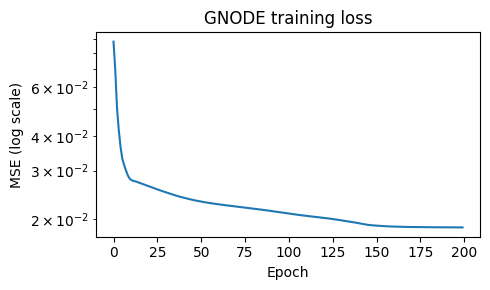

In [ ]:


# Plot loss curve
plt.figure(figsize=(5,3))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (log scale)")
plt.title("GNODE training loss")
plt.tight_layout()
plt.savefig("gnode_event3_loss.png", dpi=150)
print("Saved loss plot -> gnode_event3_loss.png")

# Save predictions for later analysis
np.save("gnode_event3_pred_x1.npy", x1_hat)
np.save("gnode_event3_true_x1.npy", x1_true)
print("Saved predictions -> gnode_event3_pred_x1.npy and true -> gnode_event3_true_x1.npy")

# Optional: print a quick spectral check for shared poem movement
try:
    from scipy.sparse.linalg import eigs
    # compute Laplacian eigenvectors for PRE and EVENT adjacency (union)
    from scipy.sparse import csr_matrix
    A_prev_np = A_prev_union
    A_evt_np  = A_evt_union
    # normalized Laplacian
    import scipy.sparse.csgraph as cs
    L_prev = cs.laplacian(csr_matrix(A_prev_np), normed=True)
    L_evt  = cs.laplacian(csr_matrix(A_evt_np),  normed=True)
    vals_prev, vecs_prev = eigs(L_prev, k=4, which='SM')
    vals_evt,  vecs_evt  = eigs(L_evt,  k=4, which='SM')
    # take second..fourth eigenvectors
    coords_prev = vecs_prev[:,1:4].real
    coords_evt  = vecs_evt[:,1:4].real
    if len(shared)>0:
        ui = idx_union[shared[0]]
        print("Spectral coords PRE (shared):", coords_prev[ui,:])
        print("Spectral coords EVT  (shared):", coords_evt[ui,:])
        print("Spectral L2 shift:", np.linalg.norm(coords_prev[ui,:]-coords_evt[ui,:]))
except Exception as ex:
    print("Spectral check failed:", ex)

print("Done.")
